# Groups

In [1]:
# datascience
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import warnings
warnings.simplefilter(action='ignore',category=np.exceptions.VisibleDeprecationWarning)


In [2]:
# polars
import polars as pl
from IPython.display import display
import hvplot.polars


## Prediction Example

In [3]:
# datascience
families = Table.read_table('family_heights.csv')
families


family,father,mother,child,children,order,child m/f
1,78.5,67,73.2,4,1,male
1,78.5,67,69.2,4,2,female
1,78.5,67,69,4,3,female
1,78.5,67,69,4,4,female
2,75.5,66.5,73.5,4,1,male
2,75.5,66.5,72.5,4,2,male
2,75.5,66.5,65.5,4,3,female
2,75.5,66.5,65.5,4,4,female
3,75,64,71,2,1,male
3,75,64,68,2,2,female


In [4]:
# polars
families_pl = pl.read_csv('family_heights.csv', infer_schema_length=10000)
families_pl


family,father,mother,child,children,order,child m/f
str,f64,f64,f64,i64,i64,str
"""1""",78.5,67.0,73.2,4,1,"""male"""
"""1""",78.5,67.0,69.2,4,2,"""female"""
"""1""",78.5,67.0,69.0,4,3,"""female"""
"""1""",78.5,67.0,69.0,4,4,"""female"""
"""2""",75.5,66.5,73.5,4,1,"""male"""
…,…,…,…,…,…,…
"""203""",62.0,66.0,64.0,3,1,"""male"""
"""203""",62.0,66.0,62.0,3,2,"""female"""
"""203""",62.0,66.0,61.0,3,3,"""female"""


In [5]:
# datascience
parent_avgs = (families.column('father') + families.column('mother'))/2


In [6]:
# polars
parent_avgs_pl = (families_pl.get_column('father') + families_pl.get_column('mother'))/2


In [7]:
# datascience
heights = Table().with_columns(
    'Parent Average', parent_avgs,
    'Child', families.column('child'), # At adulthood
    'M/F', families.column('child m/f')
)
heights


Parent Average,Child,M/F
72.75,73.2,male
72.75,69.2,female
72.75,69,female
72.75,69,female
71,73.5,male
71,72.5,male
71,65.5,female
71,65.5,female
69.5,71,male
69.5,68,female


In [8]:
# polars
heights_pl = pl.DataFrame([
    (parent_avgs_pl).alias('Parent Average'),
    (families_pl.get_column('child')).alias('Child'),
    (families_pl.get_column('child m/f')).alias('M/F')
])
heights_pl


Parent Average,Child,M/F
f64,f64,str
72.75,73.2,"""male"""
72.75,69.2,"""female"""
72.75,69.0,"""female"""
72.75,69.0,"""female"""
71.0,73.5,"""male"""
…,…,…
64.0,64.0,"""male"""
64.0,62.0,"""female"""
64.0,61.0,"""female"""


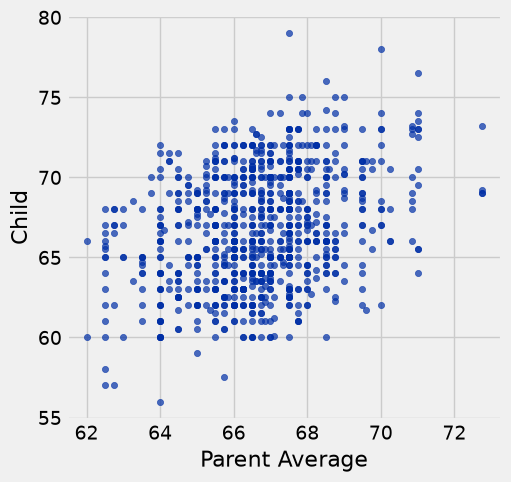

In [9]:
# datascience
heights.scatter('Parent Average', 'Child')


In [10]:
# polars
# hvplot
heights_pl.hvplot.scatter(x='Parent Average', y='Child')


:Scatter   [Parent Average]   (Child)

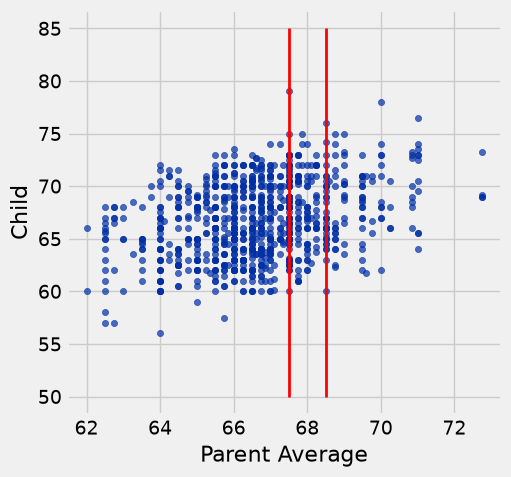

In [11]:
# datascience
heights.scatter('Parent Average', 'Child')
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2);


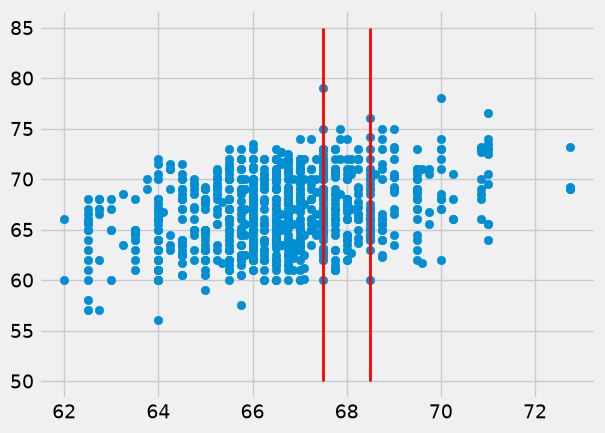

In [12]:
# polars
# matplotlib
plots.scatter(heights_pl.get_column('Parent Average'), heights_pl.get_column('Child'))
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2);


In [13]:
# datascience
nearby = heights.where('Parent Average', are.between(67.5, 68.5))
nearby_mean = np.average(nearby.column('Child'))
nearby_mean


67.620000000000005

In [14]:
# polars
nearby_pl = heights_pl.filter(pl.col('Parent Average').is_between(67.5, 68.5, closed='left'))
nearby_mean_pl = (nearby_pl.get_column('Child')).mean()
nearby_mean_pl


67.62

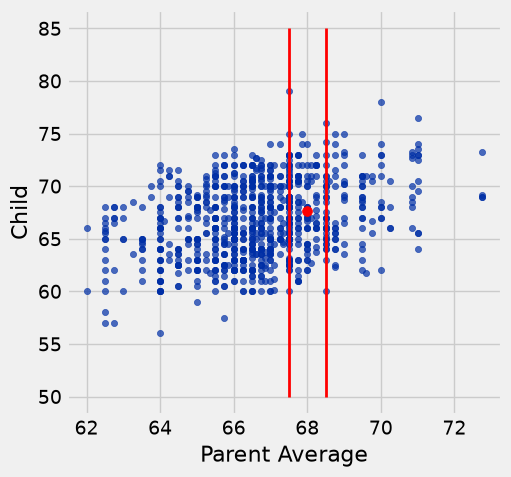

In [15]:
# datascience
heights.scatter('Parent Average', 'Child')
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2)
plots.scatter(68, nearby_mean, color='red', s=50);


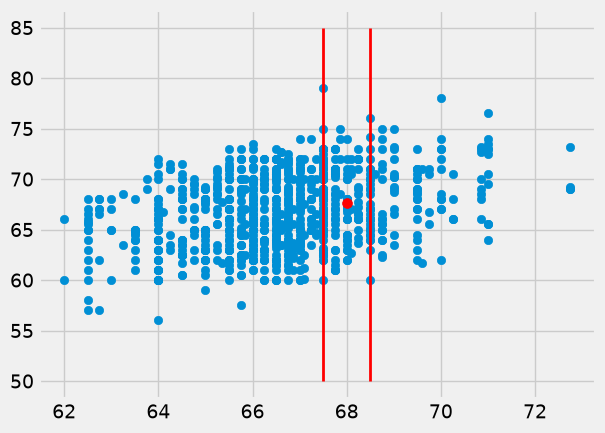

In [16]:
# polars
# matplotlib
plots.scatter(heights_pl.get_column('Parent Average'), heights_pl.get_column('Child'))
plots.plot([67.5, 67.5], [50, 85], color='red', lw=2)
plots.plot([68.5, 68.5], [50, 85], color='red', lw=2)
plots.scatter(68, nearby_mean_pl, color='red', s=50);


<br/><br/><br/>

### How can we predict the height of an adult child from their parents' average height?

In [17]:
# datascience
def predict(h):
    nearby = heights.where('Parent Average', are.between(h - 1/2, h + 1/2))
    return np.average(nearby.column('Child'))


In [18]:
# polars
def predict_pl(h):
    nearby_pl = heights_pl.filter(pl.col('Parent Average').is_between(h - 1/2, h + 1/2, closed='left'))
    return (nearby_pl.get_column('Child')).mean()


In [19]:
predict(68)

67.620000000000005

In [20]:
predict(70)

68.561904761904756

In [21]:
predict(73)

70.099999999999994

In [22]:
# datascience
predicted_heights = heights.apply(predict, 'Parent Average')


In [23]:
# polars
predicted_heights_pl = heights_pl.get_column('Parent Average').map_elements(predict_pl, return_dtype=pl.Float64)


In [24]:
# datascience
heights = heights.with_column('Prediction', predicted_heights)
heights


Parent Average,Child,M/F,Prediction
72.75,73.2,male,70.1
72.75,69.2,female,70.1
72.75,69,female,70.1
72.75,69,female,70.1
71,73.5,male,70.4158
71,72.5,male,70.4158
71,65.5,female,70.4158
71,65.5,female,70.4158
69.5,71,male,68.5025
69.5,68,female,68.5025


In [25]:
# polars
heights_pl = heights_pl.with_columns((predicted_heights_pl).alias('Prediction'))
heights_pl


Parent Average,Child,M/F,Prediction
f64,f64,str,f64
72.75,73.2,"""male""",70.1
72.75,69.2,"""female""",70.1
72.75,69.0,"""female""",70.1
72.75,69.0,"""female""",70.1
71.0,73.5,"""male""",70.415789
…,…,…,…
64.0,64.0,"""male""",64.915
64.0,62.0,"""female""",64.915
64.0,61.0,"""female""",64.915


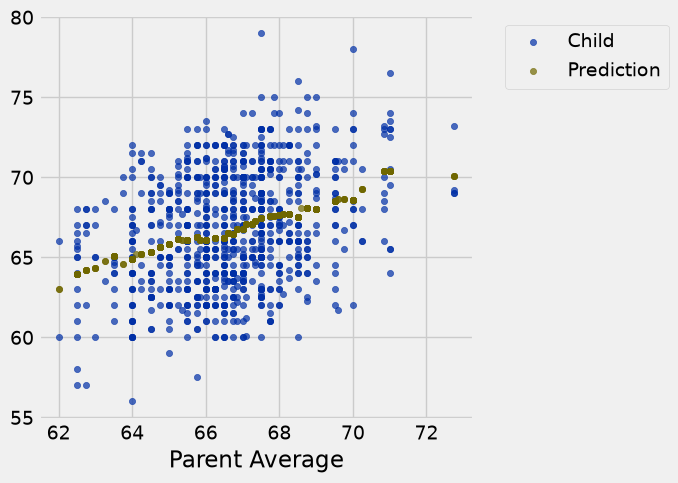

In [26]:
# datascience
heights.select('Parent Average', 'Child', 'Prediction').scatter('Parent Average')


In [27]:
# polars
# hvplot
(lambda _df: _df.hvplot.scatter(x='Parent Average', y=[c for c in _df.columns if c != 'Parent Average']))(heights_pl.select('Parent Average', 'Child', 'Prediction'))


:NdOverlay   [Variable]
   :Scatter   [Parent Average]   (value)

### Prediction Accuracy

In [28]:
# datascience
pred_errs = heights.column('Prediction') - heights.column('Child')
heights = heights.with_column('errors',pred_errs)
heights


Parent Average,Child,M/F,Prediction,errors
72.75,73.2,male,70.1,-3.1
72.75,69.2,female,70.1,0.9
72.75,69,female,70.1,1.1
72.75,69,female,70.1,1.1
71,73.5,male,70.4158,-3.08421
71,72.5,male,70.4158,-2.08421
71,65.5,female,70.4158,4.91579
71,65.5,female,70.4158,4.91579
69.5,71,male,68.5025,-2.4975
69.5,68,female,68.5025,0.5025


In [29]:
# polars
pred_errs_pl = heights_pl.get_column('Prediction') - heights_pl.get_column('Child')
heights_pl = heights_pl.with_columns(pl.Series('errors', pred_errs_pl))
heights_pl


Parent Average,Child,M/F,Prediction,errors
f64,f64,str,f64,f64
72.75,73.2,"""male""",70.1,-3.1
72.75,69.2,"""female""",70.1,0.9
72.75,69.0,"""female""",70.1,1.1
72.75,69.0,"""female""",70.1,1.1
71.0,73.5,"""male""",70.415789,-3.084211
…,…,…,…,…
64.0,64.0,"""male""",64.915,0.915
64.0,62.0,"""female""",64.915,2.915
64.0,61.0,"""female""",64.915,3.915


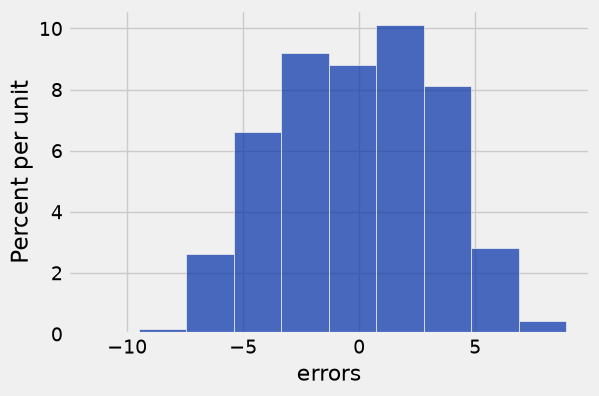

In [30]:
# datascience
heights.hist('errors')


In [31]:
# polars
# hvplot
heights_pl.hvplot.hist(y='errors', normed=True)


:Histogram   [errors]   (Frequency)

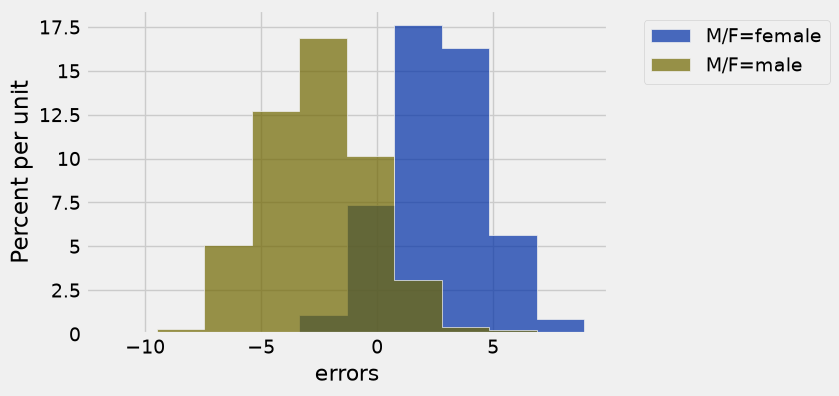

In [32]:
# datascience
heights.hist('errors', group='M/F')


In [33]:
# polars
# hvplot
heights_pl.hvplot.hist(y='errors', normed=True, by='M/F')


:NdOverlay   [M/F]
   :Histogram   [errors]   (Frequency)

**DISCUSS**: What does this chart visualize?

### Predict by height and sex

Find the average of the neighbors from the same sex

In [34]:
# datascience
def predict_smarter(h, s):
    nearby = heights.where('Parent Average', are.between(h - 1/2, h + 1/2))
    nearby_same_mf = nearby.where('M/F', s)
    return np.average(nearby_same_mf.column('Child'))


In [35]:
# polars
def predict_smarter_pl(h, s):
    nearby_pl = heights_pl.filter(pl.col('Parent Average').is_between(h - 1/2, h + 1/2, closed='left'))
    nearby_same_mf = nearby_pl.filter((pl.col('M/F') == (s)))
    return (nearby_same_mf.get_column('Child')).mean()


In [36]:
predict_smarter(68, 'female')

64.983516483516482

In [37]:
predict_smarter(68, 'male')

70.172340425531914

In [38]:
# datascience
heights.apply(predict_smarter, "Parent Average", "M/F")


array([ 73.2       ,  69.06666667,  69.06666667,  69.06666667,
        73.48888889,  73.48888889,  67.65      ,  67.65      ,
        70.79545455,  65.7       ,  70.79545455,  70.79545455,
        65.7       ,  65.7       ,  65.7       ,  69.25322581,
        69.25322581,  69.25322581,  63.59495798,  63.59495798,
        63.59495798,  67.65      ,  73.48888889,  73.48888889,
        73.48888889,  73.48888889,  67.65      ,  67.65      ,
        66.82      ,  66.82      ,  66.82      ,  66.82      ,
        65.75882353,  70.17234043,  70.17234043,  64.98351648,
        64.98351648,  64.98351648,  64.98351648,  64.98351648,
        64.98351648,  64.67788462,  71.00952381,  66.11428571,
        71.00952381,  71.00952381,  71.00952381,  71.00952381,
        65.75882353,  70.921875  ,  70.921875  ,  70.921875  ,
        70.921875  ,  70.921875  ,  65.30571429,  65.30571429,
        65.30571429,  65.30571429,  70.79047619,  70.79047619,
        70.79047619,  70.79047619,  65.44318182,  65.44

In [39]:
# polars
heights_pl.select(pl.struct(["Parent Average", "M/F"]).map_elements(lambda row: predict_smarter_pl(row["Parent Average"], row["M/F"]), return_dtype=pl.Float64)).to_series()


Parent Average
f64
73.2
69.066667
69.066667
69.066667
73.488889
…
67.33
62.5
62.5


In [40]:
# datascience
smarter_predicted_heights = heights.apply(predict_smarter, 'Parent Average', 'M/F')
heights = heights.with_column('Smarter Prediction', smarter_predicted_heights)
heights


Parent Average,Child,M/F,Prediction,errors,Smarter Prediction
72.75,73.2,male,70.1,-3.1,73.2
72.75,69.2,female,70.1,0.9,69.0667
72.75,69,female,70.1,1.1,69.0667
72.75,69,female,70.1,1.1,69.0667
71,73.5,male,70.4158,-3.08421,73.4889
71,72.5,male,70.4158,-2.08421,73.4889
71,65.5,female,70.4158,4.91579,67.65
71,65.5,female,70.4158,4.91579,67.65
69.5,71,male,68.5025,-2.4975,70.7955
69.5,68,female,68.5025,0.5025,65.7


In [41]:
# polars
smarter_predicted_heights_pl = heights_pl.select(pl.struct(['Parent Average', 'M/F']).map_elements(lambda row: predict_smarter_pl(row['Parent Average'], row['M/F']), return_dtype=pl.Float64)).to_series()
heights_pl = heights_pl.with_columns(pl.Series('Smarter Prediction', smarter_predicted_heights_pl))
heights_pl


Parent Average,Child,M/F,Prediction,errors,Smarter Prediction
f64,f64,str,f64,f64,f64
72.75,73.2,"""male""",70.1,-3.1,73.2
72.75,69.2,"""female""",70.1,0.9,69.066667
72.75,69.0,"""female""",70.1,1.1,69.066667
72.75,69.0,"""female""",70.1,1.1,69.066667
71.0,73.5,"""male""",70.415789,-3.084211,73.488889
…,…,…,…,…,…
64.0,64.0,"""male""",64.915,0.915,67.33
64.0,62.0,"""female""",64.915,2.915,62.5
64.0,61.0,"""female""",64.915,3.915,62.5


In [42]:
# datascience
def difference(child, prediction):
    return prediction - child

smarter_pred_errs = heights.apply(difference, 'Child', 'Smarter Prediction')
heights = heights.with_column('Smarter Errors', smarter_pred_errs)


In [43]:
# polars
smarter_pred_errs_pl = heights_pl.select(pl.struct(['Child', 'Smarter Prediction']).map_elements(lambda row: difference(row['Child'], row['Smarter Prediction']), return_dtype=pl.Float64)).to_series()
heights_pl = heights_pl.with_columns(pl.Series('Smarter Errors', smarter_pred_errs_pl))


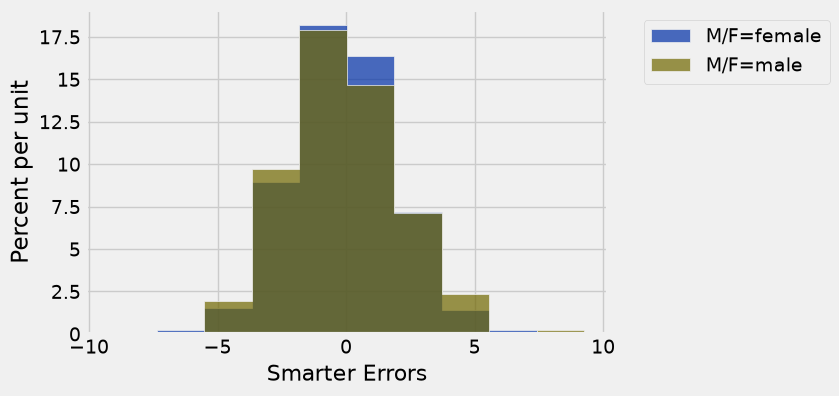

In [44]:
# datascience
heights.hist('Smarter Errors', group='M/F')


In [45]:
# polars
# hvplot
heights_pl.hvplot.hist(y='Smarter Errors', normed=True, by='M/F')


:NdOverlay   [M/F]
   :Histogram   [Smarter Errors]   (Frequency)

## Grouping by One Column

In [46]:
# datascience
cones = Table.read_table('cones.csv').drop('Color')
cones


Flavor,Price
strawberry,3.55
chocolate,4.75
chocolate,5.25
strawberry,5.25
chocolate,5.25
bubblegum,4.75


In [47]:
# polars
cones_pl = pl.read_csv('cones.csv').drop('Color')
cones_pl


Flavor,Price
str,f64
"""strawberry""",3.55
"""chocolate""",4.75
"""chocolate""",5.25
"""strawberry""",5.25
"""chocolate""",5.25
"""bubblegum""",4.75


In [48]:
# datascience
cones.group('Flavor')


Flavor,count
bubblegum,1
chocolate,3
strawberry,2


In [49]:
# polars
cones_pl.group_by('Flavor').len(name='count').sort('Flavor')


Flavor,count
str,u32
"""bubblegum""",1
"""chocolate""",3
"""strawberry""",2


In [50]:
# datascience
cones.group('Flavor', np.average)


Flavor,Price average
bubblegum,4.75
chocolate,5.08333
strawberry,4.4


In [51]:
# polars
(lambda _df: _df.group_by('Flavor').agg([getattr(pl.col(c), 'mean')().alias(f'{c} average') for c, t in _df.schema.items() if c not in ('Flavor' if isinstance('Flavor', list) else ['Flavor']) and (t.is_numeric())]).sort('Flavor'))(cones_pl)


Flavor,Price average
str,f64
"""bubblegum""",4.75
"""chocolate""",5.083333
"""strawberry""",4.4


In [52]:
# datascience
cones.group('Flavor', np.min)


Flavor,Price min
bubblegum,4.75
chocolate,4.75
strawberry,3.55


In [53]:
# polars
(lambda _df: _df.group_by('Flavor').agg([pl.col(c).min().alias(f'{c} min') for c, t in _df.schema.items() if c not in ('Flavor' if isinstance('Flavor', list) else ['Flavor']) and (getattr(t, 'is_numeric', lambda: True)())]).sort('Flavor'))(cones_pl)


Flavor,Price min
str,f64
"""bubblegum""",4.75
"""chocolate""",4.75
"""strawberry""",3.55


In [54]:
# datascience
cones.group('Flavor', np.array)


Flavor,Price array
bubblegum,[ 4.75]
chocolate,[ 4.75 5.25 5.25]
strawberry,[ 3.55 5.25]


In [55]:
# polars
(lambda _df: _df.group_by('Flavor').agg([pl.col(c).alias(f'{c} array') for c, t in _df.schema.items() if c not in ('Flavor' if isinstance('Flavor', list) else ['Flavor']) and (True)]).sort('Flavor'))(cones_pl)


Flavor,Price array
str,list[f64]
"""bubblegum""",[4.75]
"""chocolate""","[4.75, 5.25, 5.25]"
"""strawberry""","[3.55, 5.25]"


### Grouping By One Column: Welcome Survey

In [56]:
# datascience
survey = Table.read_table('welcome_survey_fa26.csv')
survey.show(3)


Extroversion,Text Recipients,Sleep Hours,Handedness,Sleep Position,Piercings
7,5,6,Right-handed,On your right side,0
7,10,7,both i switch for different things,On your right side,2
3,7,9,Left-handed,On your left side,0


In [57]:
# polars
survey_pl = pl.read_csv('welcome_survey_fa26.csv')
survey_pl.head(3)


Extroversion,Text Recipients,Sleep Hours,Handedness,Sleep Position,Piercings
i64,i64,f64,str,str,i64
7,5,6.0,"""Right-handed""","""On your right side""",0
7,10,7.0,"""both i switch for different th…","""On your right side""",2
3,7,9.0,"""Left-handed""","""On your left side""",0


In [58]:
# datascience
survey.num_rows


1122

In [59]:
# polars
survey_pl.height


1122

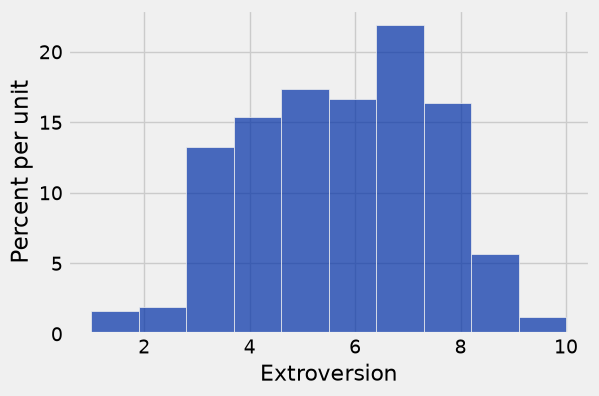

In [60]:
# datascience
survey.hist('Extroversion')


In [61]:
# polars
# hvplot
survey_pl.hvplot.hist(y='Extroversion', normed=True)


:Histogram   [Extroversion]   (Frequency)

In [62]:
# datascience
survey.group('Extroversion', np.average)


Extroversion,Text Recipients average,Sleep Hours average,Handedness average,Sleep Position average,Piercings average
1,4.5,6.84375,,,2.5625
2,4.10526,6.92105,,,0.578947
3,4.84328,6.91418,,,1.31343
4,5.57419,7.09806,,,1.57419
5,6.32,6.94571,,,1.26286
6,6.43452,7.09524,,,1.15476
7,7.84615,7.16968,,,1.40724
8,8.83636,7.01515,,,1.52727
9,11.6316,7.07895,,,1.68421
10,11.9167,6.70833,,,1


In [63]:
# polars
(lambda _df: _df.group_by('Extroversion').agg([getattr(pl.col(c), 'mean')().alias(f'{c} average') for c, t in _df.schema.items() if c not in ('Extroversion' if isinstance('Extroversion', list) else ['Extroversion']) and (t.is_numeric())]).sort('Extroversion'))(survey_pl)


Extroversion,Text Recipients average,Sleep Hours average,Piercings average
i64,f64,f64,f64
1,4.5,6.84375,2.5625
2,4.105263,6.921053,0.578947
3,4.843284,6.914179,1.313433
4,5.574194,7.098065,1.574194
5,6.32,6.945714,1.262857
6,6.434524,7.095238,1.154762
7,7.846154,7.169683,1.40724
8,8.836364,7.015152,1.527273
9,11.631579,7.078947,1.684211


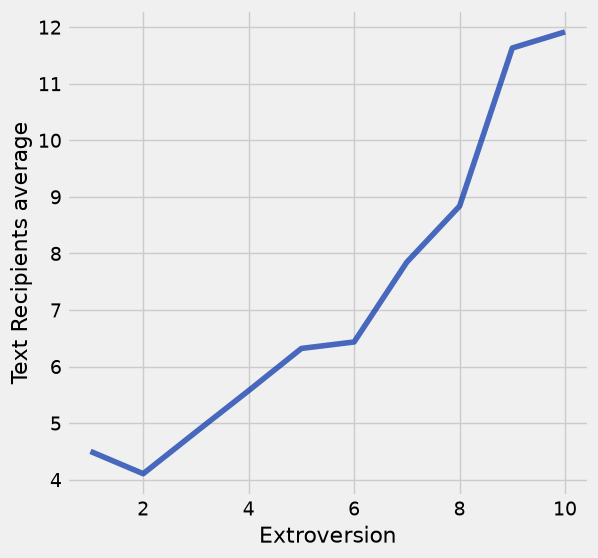

In [64]:
# datascience
survey.group('Extroversion', np.average).plot('Extroversion', 'Text Recipients average')


In [65]:
# polars
# hvplot
(lambda _df: _df.group_by('Extroversion').agg([getattr(pl.col(c), 'mean')().alias(f'{c} average') for c, t in _df.schema.items() if c not in ('Extroversion' if isinstance('Extroversion', list) else ['Extroversion']) and (t.is_numeric())]).sort('Extroversion'))(survey_pl).hvplot.line(x='Extroversion', y='Text Recipients average')


:Curve   [Extroversion]   (Text Recipients average)

## Lists

In [66]:
[1, 5, 'hello', 5.0]

[1, 5, 'hello', 5.0]

In [67]:
# datascience
[1, 5, 'hello', 5.0, make_array(1,2,3)]


[1, 5, 'hello', 5.0, array([1, 2, 3])]

In [68]:
# polars
[1, 5, 'hello', 5.0, pl.Series('values', [1,2,3])]


[1,
 5,
 'hello',
 5.0,
 shape: (3,)
 Series: 'values' [i64]
 [
 	1
 	2
 	3
 ]]

## Grouping by Two Columns

Do right-handed people tend to sleep on their left side and left-handed people sleep on their right?

In [69]:
# datascience
survey.group('Sleep Position')


Sleep Position,count
On your back,333
On your left side,301
On your right side,368
On your stomach,120


In [70]:
# polars
survey_pl.group_by('Sleep Position').len(name='count').sort('Sleep Position')


Sleep Position,count
str,u32
"""On your back""",333
"""On your left side""",301
"""On your right side""",368
"""On your stomach""",120


In [71]:
# datascience
survey.group(['Handedness', 'Sleep Position']).show()


Handedness,Sleep Position,count
Ambidexterous,On your right side,1
"Born Left, Taught Right for writing, rest is mainly left.",On your right side,1
Both,On your back,1
"Functionally right handed, naturally left handed, result ...",On your left side,1
I can write with both hands and feet,On your back,1
I'm ambidextrous,On your back,1
Left-handed,On your back,20
Left-handed,On your left side,33
Left-handed,On your right side,29
Left-handed,On your stomach,13


In [72]:
# polars
with pl.Config(tbl_rows=-1):
    display(survey_pl.group_by(['Handedness', 'Sleep Position']).len(name='count').sort(['Handedness', 'Sleep Position']))


Handedness,Sleep Position,count
str,str,u32
"""Ambidexterous""","""On your right side""",1
"""Born Left, Taught Right for wr…","""On your right side""",1
"""Both""","""On your back""",1
"""Functionally right handed, nat…","""On your left side""",1
"""I can write with both hands an…","""On your back""",1
"""I'm ambidextrous""","""On your back""",1
"""Left-handed""","""On your back""",20
"""Left-handed""","""On your left side""",33
"""Left-handed""","""On your right side""",29
